In [119]:
# for package auto reload
%load_ext autoreload
%autoreload 2

%matplotlib inline

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [159]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics
from sklearn.model_selection import train_test_split
#calibration
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import brier_score_loss

## Data Analysis
### EDA and Preprocessing

In [122]:
dataset_path = "hotel_bookings.csv"
df = pd.read_csv(dataset_path, delimiter=',', low_memory=False)

df.head(7)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03
6,Resort Hotel,0,0,2015,July,27,1,0,2,2,...,No Deposit,NaN,NaN,0,Transient,107.0,0,0,Check-Out,2015-07-03


In [123]:
df.shape

(119390, 32)

In [124]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='str')

In [125]:
df = df.rename(columns ={"adr": "price_per_night"})
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'price_per_night',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='str')

In [126]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [128]:
values0, values1 = df['is_canceled'].value_counts()
percentage0, percentage1 = df['is_canceled'].value_counts(normalize=True) #Normalized to have the percentage 

print(f"# canceled bookings: {values1} and # not canceled bookings: {values0}")
print (f"Percentage of canceled bookings: {percentage0:.2f}%")
print (f"Percentage of not canceled bookings: {percentage1:.2f}%")



# canceled bookings: 44224 and # not canceled bookings: 75166
Percentage of canceled bookings: 0.63%
Percentage of not canceled bookings: 0.37%


In [129]:
# Checking number of different values in country column
df['country'].value_counts()

country
PRT    48590
GBR    12129
FRA    10415
ESP     8568
DEU     7287
       ...  
NCL        1
KIR        1
SDN        1
ATF        1
SLE        1
Name: count, Length: 177, dtype: int64

### Null values

In [130]:
def display_null(df):
        null = df.isnull().sum().sort_values(ascending=False)
        for x in null.index:
            if null[x] > 0:
                print(f"{x}: {null[x]/len(df)*100:.4f}% missing values")

        if null.sum() == 0:
            print("No missing values in the dataset")
        
       
  
display_null(df)


company: 94.3069% missing values
agent: 13.6862% missing values
country: 0.4087% missing values
children: 0.0034% missing values


In [131]:
#First create a column called "Booked through company" with 0 and 1 ,0 for no and 1 for yes.
#Then drop company column since it has 94.3% missing values
df["has_company"] = df["company"].notnull().astype(int)
df = df.drop(columns=['company'])

# Fill missing values in agent column with 0 since it is a categorical variable
df['agent'] = df['agent'].fillna(0).astype(str)

# Fill missing values in country column with 'Unknown'
df['country'] = df['country'].fillna('Unknown')

# Fill missing values in children column with 0 since it's less than 1%
df['children'] = df['children'].fillna(0).astype(int)


In [132]:
#check the null values again
display_null(df)

No missing values in the dataset


### Wiered values 

In [133]:
df["price_per_night"].describe()

count    119390.000000
mean        101.831122
std          50.535790
min          -6.380000
25%          69.290000
50%          94.575000
75%         126.000000
max        5400.000000
Name: price_per_night, dtype: float64

In [134]:
# First count rows with impossible prices
negative = (df["price_per_night"] < 0).sum()
too_high = (df["price_per_night"] > 1000).sum()
zero = (df["price_per_night"] == 0).sum()

print(f"Negative ADR: {negative} rows")
print(f"ADR above 1000: {too_high} rows")
print(f"ADR equal to 0: {zero} rows")

Negative ADR: 1 rows
ADR above 1000: 1 rows
ADR equal to 0: 1959 rows


In [135]:
# Now drop the rows with 0, negative, and too high prices
df = df[(df["price_per_night"] >= 0) & (df["price_per_night"] <= 1000)]

### Data leakage <br>


In [136]:
# Dropping: 
# reservation_status takes the values Canceled / Check-Out / No-Show. It is the answer. 
# reservation_status_date is the date that status was set, so it’s only known after the outcome. 
# assigned_room_type is decided at check-in, which is after the booking.
df = df.drop(columns=['reservation_status', 'reservation_status_date','assigned_room_type'])

### Column choice

In [137]:
# creating a total night column by adding the number of weekend nights and the number of week nights
df['total_nights']= df['stays_in_weekend_nights'] + df['stays_in_week_nights']
print(df['total_nights'].head(5)) #checking

# Group countries that represent less than 1% of booking into a single category called "Other"
n = 0.01*len(df)
counts = df['country'].value_counts()
rare_countries = counts[counts < n].index
df['country'] = df['country'].replace(rare_countries, 'Other')
print('number of differnt country values = ', df['country'].nunique()) # cheking

# Creating a new column called "arrival_week_of_month", using "arrival_date_day_of_month" to know which week of the month the arrival date falls into.
df["arrival_week_of_month"] = ((df["arrival_date_day_of_month"] - 1) // 7 + 1).clip(upper=4)
# and dropping the "arrival_date_day_of_month" column since for example week of 52 means the same as first week of month .


0    0
1    0
2    1
3    1
4    2
Name: total_nights, dtype: int64
number of differnt country values =  15


### Train and Validation set

Taking the most recent 20% of the data as the test set and the next recent 20% as validation set, and the remaining 60% as the training set

In [141]:
#Making a new column with all the dates merged to use in spliting the dataset
df["arrival_date"] = pd.to_datetime(
    df["arrival_date_year"].astype(str) + "-" +
    df["arrival_date_month"] + "-" +
    df["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d"
)
# Order the data from the most recent
n = len(df)
df = df.sort_values(by ="arrival_date")

X = df.drop(columns=['is_canceled'])
y = df['is_canceled'] 

x_train = X.iloc[: int(n*0.6)]
x_val = X.iloc[int(n*0.6) : int(n*0.8) ]
x_test = X.iloc[int(n*0.8) :]

y_train = y.iloc[: int(n*0.6)]
y_val = y.iloc[int(n*0.6) : int(n*0.8) ]
y_test = y.iloc[int(n*0.8) :]

for name, part in [("Train set", x_train), ("Validation set", x_val), ("Test set", x_test)]:
    print(name, "length:", len(part),"from", part["arrival_date"].min().date(), "to",
          part["arrival_date"].max().date())


Train set length: 71632 from 2015-07-01 to 2016-11-07
Validation set length: 23878 from 2016-11-07 to 2017-04-22
Test set length: 23878 from 2017-04-22 to 2017-08-31


The training period is mostly summer and autumn of 2015 and 2016, Validation is november 2016 to april 2017 which is mostly winter and spring and test set is summer 

##### Numerical and Categorical columns of training data

In [142]:
num_cols = x_train.select_dtypes(include="number").columns.tolist()
cat_cols = x_train.select_dtypes(exclude="number").columns.tolist()

print("Numerical:", num_cols)
print("Categorical:", cat_cols)

Numerical: ['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'price_per_night', 'required_car_parking_spaces', 'total_of_special_requests', 'has_company', 'total_nights', 'arrival_week_of_month']
Categorical: ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'agent', 'customer_type', 'arrival_date']


### Change the categorical columns to numerical columns for the random forest model

In [ ]:
 # reindex is used to ensure that the validate and test sets have the same columns as the training set
x_train_rf = pd.get_dummies(x_train, columns=cat_cols)
x_val_rf   = pd.get_dummies(x_val,   columns=cat_cols).reindex(columns=x_train_rf.columns, fill_value=0)
x_test_rf = pd.get_dummies(x_test,  columns=cat_cols).reindex(columns=x_train_rf.columns, fill_value=0)

### Fit the model

In [144]:
rf = RandomForestClassifier()
rf.fit(x_train_rf, y_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

### Function of the performance for the classification model.

In [ ]:
def base_classif_perf(y_true, y_pred, positive_label = 1) -> None:
    """
    Evaluate the performance of the classification model.
    Recall shows out of all the real cancellations how many did the model catch.
    Precision shows when the model says it will cancel how often is it right.

    """   
    print("Accuracy : {:.3f}".format(metrics.accuracy_score(y_true, y_pred)))
    print("Recall : {:.3f}".format(metrics.recall_score(y_true, y_pred, pos_label=positive_label)))
    print("Precision : {:.3f}".format(metrics.precision_score(y_true, y_pred, pos_label=positive_label)))
    print("F1 score : {:.3f}".format(metrics.f1_score(y_true, y_pred, pos_label=positive_label)))
    return

In [ ]:
threshold = 0.27

prob_train = rf.predict_proba(x_train_rf)[:, 1]   #gives each booking's chance of cancelling 
prob_val = rf.predict_proba(x_val_rf)[:, 1]
prob_test = rf.predict_proba(x_test_rf)[:,1]

predi_train = (prob_train>= threshold).astype(int)   # compares each one to the cut off and give 1 if above the threshold and 0 if below
predi_val = (prob_val>= threshold).astype(int) 
predi_test = (prob_test>= threshold).astype(int)

print("TRAIN")
base_classif_perf(y_train, predi_train)
print("\nVALIDATION")
base_classif_perf(y_val, predi_val)

TRAIN
Accuracy : 0.988
Recall : 0.997
Precision : 0.970
F1 score : 0.983

VALIDATION
Accuracy : 0.811
Recall : 0.776
Precision : 0.711
F1 score : 0.742


### Calibration 

Brier raw:        0.1328
Brier calibrated: 0.1393

Threshold: 0.5
Accuracy : 0.797
Recall : 0.525
Precision : 0.832
F1 score : 0.644

Threshold: 0.4
Accuracy : 0.807
Recall : 0.606
Precision : 0.792
F1 score : 0.687

Threshold: 0.3
Accuracy : 0.806
Recall : 0.706
Precision : 0.730
F1 score : 0.718

Threshold: 0.27
Accuracy : 0.800
Recall : 0.731
Precision : 0.707
F1 score : 0.719


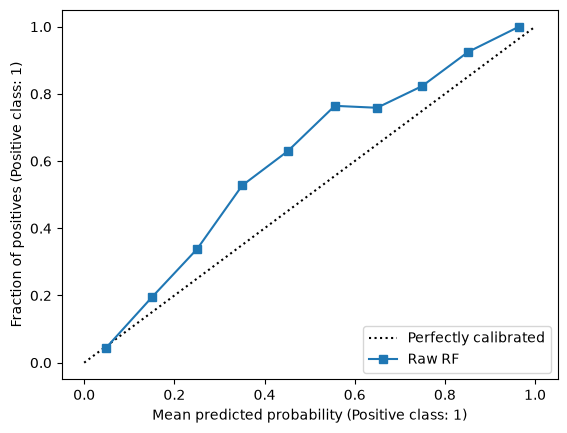

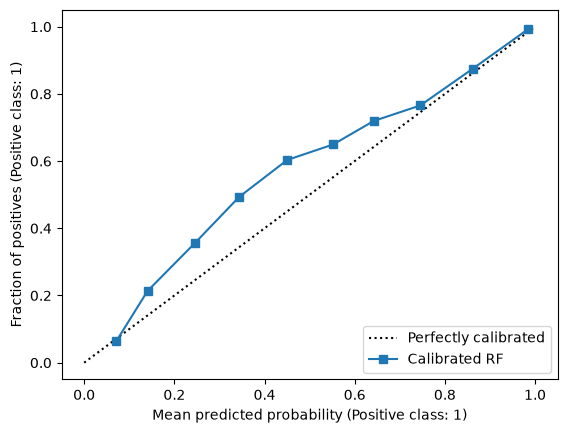

In [ ]:
#Building calibratied model from rf
cal_rf = CalibratedClassifierCV(
    RandomForestClassifier(random_state=45, n_jobs=-1 ), #same setting as rf
    method = 'sigmoid',
    cv=TimeSeriesSplit(n_splits=5)
)
cal_rf.fit(x_train_rf,y_train)

# now comparing raw vs calibrated probabilities on validation set 
prob_raw = rf.predict_proba(x_val_rf)[:, 1]
prob_cal = cal_rf.predict_proba(x_val_rf)[:, 1]

# Brier shows hoe close the model's probailites are to what really happened, so the lower the better 
print("Brier raw:       ", round(brier_score_loss(y_val, prob_raw), 4))
print("Brier calibrated:", round(brier_score_loss(y_val, prob_cal), 4))

#Calibration curves 
CalibrationDisplay.from_predictions(y_val, prob_raw, n_bins=10, name="Raw RF")
CalibrationDisplay.from_predictions(y_val, prob_cal, n_bins=10, name="Calibrated RF")

#choosing threshold again on calibrated probabilites
for threshold in [0.5 , 0.4 , 0.3 , 0.27]:
    print("\nThreshold:", threshold)
    base_classif_perf(y_val, (prob_cal >= threshold).astype(int))

So we can see the resault of val_set is better without hte calibration

### Tuning(hyperparameters)

In [ ]:
tuned_rf = RandomForestClassifier(
    n_estimators =30,  #number of tress
    class_weight=None,
    criterion = 'gini',  # How the tree measures a good split. Gini measures how mixed a group is (cancelled vs not cancelled). 'entropy' is the alternative and usually gives almost identical results.
    max_depth = 30, #Maximum number of questions in a row. None means no limit
    #min_samples_split = 3, #A group must contain at least n bookings to be split further
    #min_samples_leaf = 2, #Every final group must contain at least 2 bookings so bigger values mean less memorising

    max_features = None, #How many columns each split can choose from - "sqrt" (the default) picks a random subset at each split which makes the trees more varied and usually works better
    #max_leaf_nodes = None, 
    #min_impurity_decrease = 0.0,
    bootstrap = True, #	Each tree trains on a random sample of rows, drawn with replacement means some rows picked twice, some not at all
    #oob_score = True, 
    max_samples = 40000, #Each tree sees only n random rows instead of all which is faster and the trees memorise less
    random_state = 42, #it fixes the randomness to get the same resault every time
)


In [200]:
tuned_rf.fit(x_train_rf, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",30
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",30
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"max_samples max_samples: int or float, default=NoneIf bootstrap is True, the number of samples to draw from Xto train each base estimator.- If None (default), then draw `X.shape[0]` samples irrespective of `sample_weight`.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` unweighted samples or `max_samples * sample_weight.sum()` weighted samples... versionadded:: 0.22.. versionchanged:: 1.9 Float `max_samples` is relative to `sample_weight.sum()` instead of `X.shape[0]` for weighted samples.",40000
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the

In [195]:
print("Train:")
base_classif_perf(y_train, tuned_rf.predict(x_train_rf))
print("\nValidation:")
base_classif_perf(y_val, tuned_rf.predict(x_val_rf))

Train:
Accuracy : 0.961
Recall : 0.929
Precision : 0.961
F1 score : 0.945

Validation:
Accuracy : 0.813
Recall : 0.611
Precision : 0.809
F1 score : 0.696


This is the resualt by changing n_estimator from 100 to 30, max_feature from sqrt to none, max_sample from all to 40 000

#### Now trying different thresholds: 

In [196]:
threshold = 0.33

prob_train = tuned_rf.predict_proba(x_train_rf)[:, 1]
prob_val   = tuned_rf.predict_proba(x_val_rf)[:, 1]

print("TRAIN")
base_classif_perf(y_train, (prob_train >= threshold).astype(int))
print("\nVALIDATION")
base_classif_perf(y_val, (prob_val >= threshold).astype(int))

TRAIN
Accuracy : 0.959
Recall : 0.974
Precision : 0.918
F1 score : 0.945

VALIDATION
Accuracy : 0.810
Recall : 0.725
Precision : 0.729
F1 score : 0.727


### Checking precision recall and F1 by threshold plot for validation

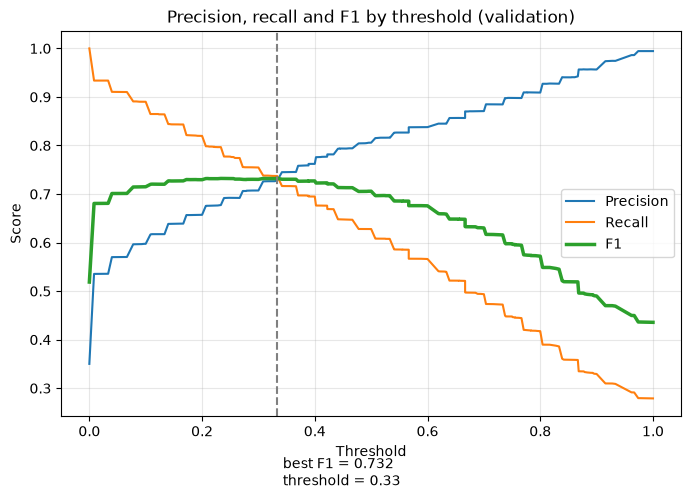

Best threshold: 0.333 | F1: 0.732 | Recall: 0.737 | Precision: 0.728


In [191]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

prob_val = tuned_rf.predict_proba(x_val_rf)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_val, prob_val)
precision, recall = precision[:-1], recall[:-1]   

f1 = 2 * precision * recall / (precision + recall + 1e-12)

best = np.argmax(f1)
best_t = thresholds[best]

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precision, label="Precision")
plt.plot(thresholds, recall, label="Recall")
plt.plot(thresholds, f1, label="F1", linewidth=2.5)
plt.axvline(best_t, color="grey", linestyle="--")
plt.text(best_t + 0.01, 0.1, f"best F1 = {f1[best]:.3f}\nthreshold = {best_t:.2f}")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision, recall and F1 by threshold (validation)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Best threshold:", round(best_t, 3), "| F1:", round(f1[best], 3),
      "| Recall:", round(recall[best], 3), "| Precision:", round(precision[best], 3))

#### Validation curve; Trying different max_depht

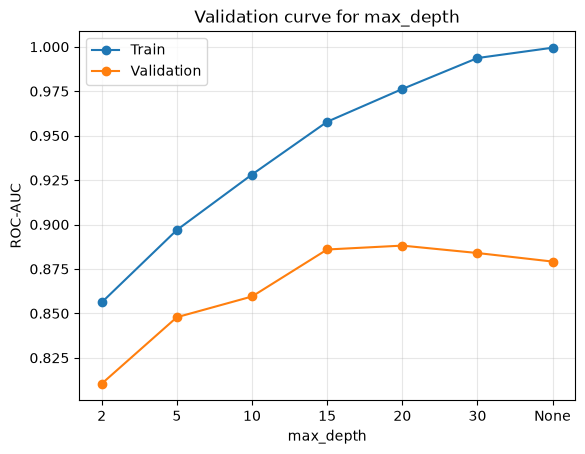

In [201]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

values = [2, 5, 10, 15, 20, 30, None]
train_scores, val_scores = [], []

for v in values:
    m = RandomForestClassifier(n_estimators=30, max_depth=v,
                               random_state=42, n_jobs=-1)
    m.fit(x_train_rf, y_train)
    train_scores.append(roc_auc_score(y_train, m.predict_proba(x_train_rf)[:, 1]))
    val_scores.append(roc_auc_score(y_val, m.predict_proba(x_val_rf)[:, 1]))

labels = [str(v) for v in values]
plt.plot(labels, train_scores, marker="o", label="Train")
plt.plot(labels, val_scores, marker="o", label="Validation")
plt.xlabel("max_depth")
plt.ylabel("ROC-AUC")
plt.title("Validation curve for max_depth")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [204]:
tuned_rf = RandomForestClassifier(
    n_estimators =30,  #number of tress
    class_weight=None,
    criterion = 'gini',  # How the tree measures a good split. Gini measures how mixed a group is (cancelled vs not cancelled). 'entropy' is the alternative and usually gives almost identical results.
    max_depth = 20, #Maximum number of questions in a row. None means no limit
    #min_samples_split = 3, #A group must contain at least n bookings to be split further
    #min_samples_leaf = 2, #Every final group must contain at least 2 bookings so bigger values mean less memorising

    max_features = None, #How many columns each split can choose from - "sqrt" (the default) picks a random subset at each split which makes the trees more varied and usually works better
    #max_leaf_nodes = None, 
    #min_impurity_decrease = 0.0,
    bootstrap = True, #	Each tree trains on a random sample of rows, drawn with replacement means some rows picked twice, some not at all
    #oob_score = True, 
    max_samples = 40000, #Each tree sees only n random rows instead of all which is faster and the trees memorise less
    random_state = 42, #it fixes the randomness to get the same resault every time
)


In [205]:
tuned_rf.fit(x_train_rf, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",30
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"max_samples max_samples: int or float, default=NoneIf bootstrap is True, the number of samples to draw from Xto train each base estimator.- If None (default), then draw `X.shape[0]` samples irrespective of `sample_weight`.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` unweighted samples or `max_samples * sample_weight.sum()` weighted samples... versionadded:: 0.22.. versionchanged:: 1.9 Float `max_samples` is relative to `sample_weight.sum()` instead of `X.shape[0]` for weighted samples.",40000
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the

In [207]:
print("Train:")
base_classif_perf(y_train, tuned_rf.predict(x_train_rf))
print("\nValidation:")
base_classif_perf(y_val, tuned_rf.predict(x_val_rf))

Train:
Accuracy : 0.939
Recall : 0.892
Precision : 0.938
F1 score : 0.914

Validation:
Accuracy : 0.815
Recall : 0.610
Precision : 0.815
F1 score : 0.697


In [208]:
threshold = 0.33

prob_train = tuned_rf.predict_proba(x_train_rf)[:, 1]
prob_val   = tuned_rf.predict_proba(x_val_rf)[:, 1]

print("TRAIN")
base_classif_perf(y_train, (prob_train >= threshold).astype(int))
print("\nVALIDATION")
base_classif_perf(y_val, (prob_val >= threshold).astype(int))

TRAIN
Accuracy : 0.939
Recall : 0.943
Precision : 0.894
F1 score : 0.918

VALIDATION
Accuracy : 0.812
Recall : 0.725
Precision : 0.734
F1 score : 0.729
